# 생성형 AI를 활용한 제조 결함 데이터 생성 프로젝트
## AnomalyAny 기반 추가 실험 및 결과 검토

이 노트북은 수업에서 제공된 AnomalyAny 실습 코드를 그대로 다시 실행하는 데서 멈추지 않고, 어떤 조건에서 결과가 달라지는지 확인하기 위해 직접 비교 실험을 설계하고 기록한 프로젝트이다.

### 프로젝트 목표
- 생성형 AI가 정상 제품 이미지에 결함을 얼마나 자연스럽게 만들 수 있는지 확인한다.
- 결함을 만들 때 정상 제품의 원래 형상이 얼마나 유지되는지 함께 본다.
- 조건을 하나씩 바꿔 보며 결과 차이를 정량적 수치와 시각적 결과로 해석한다.
- 단순히 생성되었다는 사실이 아니라, 실제 제조 데이터로 활용 가능한지 비판적으로 검토한다.

### 이번 프로젝트에서 내가 직접 해 본 것
- 기준 실험을 먼저 실행하고, 추가 비교 실험 5가지를 설계했다.
- 실행 과정에서 발생한 dtype 오류, 메모리 문제, NaN 문제를 단계적으로 수정했다.
- 생성 결과를 원본 대비 ROI / ROI 외부 변화량으로 정량 평가했다.
- 최종적으로는 자동 지표만으로 충분하지 않다고 판단해 수동 평가도 함께 기록했다.


## 1. 설정 및 실험 계획

이 셀부터는 전체 실험의 공통 설정값을 정의한다.  
여기서 Seed, 이미지 경로, 결과 저장 폴더, 실험 리스트를 정리해 두면 뒤의 코드가 같은 기준을 공유할 수 있다.

### 내가 이 부분에서 중요하게 본 점
- 실험 비교를 하려면 기준 조건을 먼저 고정해야 한다.
- 변수를 여러 개 동시에 바꾸면 결과 해석이 어려워진다.
- 그래서 기준 실험 `E00_baseline`을 만들고, 이후에는 한 번에 한 조건만 바꾸는 방식으로 설계했다.


In [8]:
from pathlib import Path

file_path = Path(
    r"C:\Users\USER\Desktop\ERICA_X_MODULABS_CV"
    r"\08_Gen_Synthetic_data\AnomalyAny"
    r"\clip_pipeline_attend_and_excite.py"
)

old_code = (
    "losses = [max(0, 1. - curr_max) "
    "for curr_max in max_attention_per_index]"
)

new_code = (
    "losses = [torch.clamp(1.0 - curr_max, min=0.0) "
    "for curr_max in max_attention_per_index]"
)

source = file_path.read_text(encoding="utf-8")

if source.count(old_code) == 1:
    # 원본 파일 백업
    backup_path = file_path.with_suffix(".py.bak")

    if not backup_path.exists():
        backup_path.write_text(source, encoding="utf-8")

    # 문제 코드 수정
    source = source.replace(old_code, new_code)
    file_path.write_text(source, encoding="utf-8")

    print("수정 완료!")
    print("수정 파일:", file_path)

elif new_code in source:
    print("이미 수정된 상태입니다.")

else:
    raise RuntimeError(
        "예상한 코드가 없습니다. 원본 파일 내용을 확인해주세요."
    )

수정 완료!
수정 파일: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data\AnomalyAny\clip_pipeline_attend_and_excite.py


In [10]:
# 이 셀은 실험 전체에서 공통으로 쓰는 기본 경로, 폴더, 실험 조건을 정의한다.
# 나중에 결과를 비교하려면 같은 기준을 유지해야 하므로, Seed와 경로를 한 곳에서 관리하도록 했다.

from pathlib import Path
from dataclasses import dataclass, asdict
import os, sys, json, time, gc, hashlib, traceback, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

# 사용자 PC의 작업 폴더. 이곳에서 기존 파일/데이터를 찾는다.
BASE_DIR = Path(r"C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data")
REPO_DIR = BASE_DIR / "AnomalyAny"
INPUT_DIR = BASE_DIR / "inputs"
OUTPUT_DIR = BASE_DIR / "results"
for folder in (BASE_DIR, INPUT_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

MODEL_ID = "runwayml/stable-diffusion-v1-5"    # 강의 8-2의 모델
ALTERNATIVE_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
NUM_DIFFUSION_STEPS = 16                       # 강의의 200보다 단축, 공통 적용
GUIDANCE_SCALE = 7.5                          # 텍스트 CFG (아래 init guidance와 다름)
SCALE_FACTOR = 20
BASE_SEED = 2026
NEW_OBJECT_NAME = "metal nut"                 # new_product 사진 속 실제 제품 이름으로 수정
NEW_IMAGE_PATH = None                      # 파일이 다른 곳에 있으면 r"C:\...\파일명.jpg" 입력
INIT_GUIDANCE_BASE = 0.30
INIT_GUIDANCE_LOW = 0.20
INIT_GUIDANCE_HIGH = 0.45
BASE_ROI = (0.34, 0.35, 0.67, 0.68)         # [x0,y0,x1,y1], 0~1
NEW_ROI = (0.40, 0.37, 0.62, 0.65)
PIXEL_CHANGE_THRESHOLD = 15
RESUME_EXISTING = True
SIDE = 512

@dataclass(frozen=True)
class Experiment:
    name: str
    group: str
    source: str
    seed: int
    use_mask: bool
    init_guidance: float
    prompt_style: str

EXPERIMENTS = [
    Experiment('E00_baseline',     'baseline',     'hazelnut', BASE_SEED,   False, INIT_GUIDANCE_BASE, 'detailed'),
    Experiment('E01_mask_on',      'mask',         'hazelnut', BASE_SEED,   True,  INIT_GUIDANCE_BASE, 'detailed'),
    Experiment('E02_simple_prompt','prompt',      'hazelnut', BASE_SEED,   False, INIT_GUIDANCE_BASE, 'simple'),
    Experiment('E03_seed_plus1',   'seed',         'hazelnut', BASE_SEED+1, False, INIT_GUIDANCE_BASE, 'detailed'),
    Experiment('E04_seed_plus2',   'seed',         'hazelnut', BASE_SEED+2, False, INIT_GUIDANCE_BASE, 'detailed'),
    Experiment('E05_new_product',  'new_product',  'new_product',BASE_SEED, False, INIT_GUIDANCE_BASE, 'detailed'),
    Experiment('E06_init_020',     'init_guidance','hazelnut', BASE_SEED,   False, INIT_GUIDANCE_LOW,  'detailed'),
    Experiment('E07_init_045',     'init_guidance','hazelnut', BASE_SEED,   False, INIT_GUIDANCE_HIGH, 'detailed'),
]

def to_rgb512(obj):
    if isinstance(obj, Image.Image):
        return obj.convert('RGB').resize((SIDE,SIDE), Image.Resampling.LANCZOS)
    with Image.open(obj) as f:
        return f.convert('RGB').resize((SIDE,SIDE), Image.Resampling.LANCZOS)

def rectangle_mask(shape, xy):
    w,h=shape
    x0,y0,x1,y1=xy
    if not (0<=x0<x1<=1 and 0<=y0<y1<=1):
        raise ValueError('ROI는 0~1 사이이고 x0<x1, y0<y1 이어야 합니다.')
    mask=Image.new('L', (w,h),0)
    ImageDraw.Draw(mask).rectangle((round(x0*w),round(y0*h),round(x1*w),round(y1*h)),fill=255)
    return mask

def build_text(exp):
    obj='hazelnut' if exp.source=='hazelnut' else NEW_OBJECT_NAME
    if not obj.strip():raise ValueError('NEW_OBJECT_NAME에 제품 이름을 입력하세요.')
    # 모든 조건에서 주 프롬프트는 고정. 프롬프트 실험은 detailed_prompt만 변경한다.
    prompt=f'a photo of a {obj} with a crack on it'
    normal=f'a photo of a {obj}'
    detailed=(f'a photo of a {obj} with a large, jagged crack exposing the interior.'
              if exp.prompt_style=='detailed' else prompt)
    return prompt,normal,detailed

def output_paths(exp):
    return OUTPUT_DIR/f'{exp.name}.png', OUTPUT_DIR/f'{exp.name}.json'

print('커널 Python:', sys.executable)
print('작업 경로:',BASE_DIR)
print('실험 조건 수:', len(EXPERIMENTS))
print('Seed 정의:', BASE_SEED)
plan=pd.DataFrame([asdict(e) for e in EXPERIMENTS])
plan.to_csv(OUTPUT_DIR/'experiment_plan.csv',index=False,encoding='utf-8-sig')
display(plan)

커널 Python: C:\Users\USER\.conda\envs\anomalyany\python.exe
작업 경로: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data
실험 조건 수: 8
Seed 정의: 2026


,name,group,source,seed,use_mask,init_guidance,prompt_style
0,E00_baseline,baseline,hazelnut,2026,False,0.30,detailed
1,E01_mask_on,mask,hazelnut,2026,True,0.30,detailed
2,E02_simple_prompt,prompt,hazelnut,2026,False,0.30,simple
3,E03_seed_plus1,seed,hazelnut,2027,False,0.30,detailed
4,E04_seed_plus2,seed,hazelnut,2028,False,0.30,detailed
5,E05_new_product,new_product,new_product,2026,False,0.30,detailed
6,E06_init_020,init_guidance,hazelnut,2026,False,0.20,detailed
7,E07_init_045,init_guidance,hazelnut,2026,False,0.45,detailed


## 2. 소스 및 입력 사진 자동 확인

이 단계는 실제 실행 전에 필요한 입력 이미지와 AnomalyAny 소스 파일이 준비되었는지 확인하는 부분이다.

### 왜 필요한가
실습에서는 코드 자체보다도 경로 문제로 많이 막혔다.  
그래서 입력 이미지와 원본 소스 파일의 존재 여부를 먼저 확인해서, 뒤에서 의미 없이 오류가 나지 않도록 했다.

### 내 생각
실제로 프로젝트를 해 보니, 모델 성능 이전에 재현 가능한 실행 환경을 만드는 것도 중요한 작업이라는 걸 느꼈다.


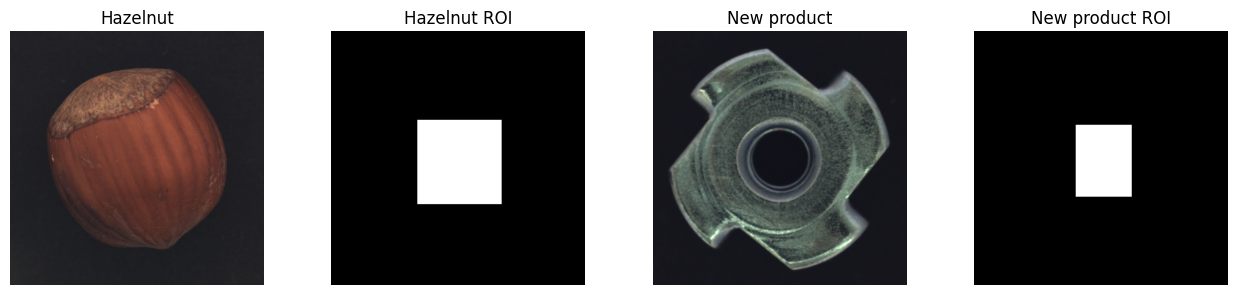

새 제품 사진을 찾았습니다: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data\inputs\new_product.jpg.jpg
소스 파일 확인: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data\AnomalyAny
실행 가능한 생성 조건: 8 / 8
신규 이미지의 물체 이름: metal nut


In [11]:
# 이 셀은 입력 이미지와 AnomalyAny 원본 소스 파일이 실제로 존재하는지 확인한다.
# 실험 중 경로 오류가 반복되어, 뒤에서 막히지 않도록 여기서 먼저 검사하게 만들었다.

assert 'BASE_SEED' in globals(), '첫 번째 설정 코드 셀을 실행하세요.'
if not (REPO_DIR/'run.py').is_file() or not (REPO_DIR/'clip_pipeline_attend_and_excite.py').is_file():
    if REPO_DIR.exists():
        raise FileNotFoundError(f'AnomalyAny 소스 일부가 없습니다: {REPO_DIR}')
    print('AnomalyAny 원본 코드를 다운로드합니다...')
    subprocess.run(['git','clone','https://github.com/EPFL-IMOS/AnomalyAny.git',str(REPO_DIR)],check=True)
for filename in ('run.py','clip_pipeline_attend_and_excite.py','config.py'):
    if not (REPO_DIR/filename).is_file():
        raise FileNotFoundError(f'원본 소스 누락: {REPO_DIR/filename}')
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0,str(REPO_DIR))
os.chdir(REPO_DIR)

base_path=REPO_DIR/'example_image'/'000.png'
if not base_path.is_file():
    raise FileNotFoundError(f'공식 예시 이미지가 없습니다: {base_path}')

# 이름 대소문자, Windows 이중 확장자, 하위 폴더를 함께 확인
from PIL import ImageOps

def looks_like_user_image(p):
    name=p.name.lower().replace('-', '_').replace(' ', '_')
    if not name.startswith('new_product'):
        return False
    if name.startswith(('new_product_512','new_product_roi_mask','new_product_procedural')):
        return False
    return p.suffix.lower() in ('.jpg','.jpeg','.png','.webp','.bmp')

def discover_new_product():
    manual=globals().get('NEW_IMAGE_PATH')
    if manual:
        manual=Path(str(manual).strip().strip('"')).expanduser()
        if manual.is_file():
            return manual
        print('NEW_IMAGE_PATH의 파일을 찾을 수 없습니다:',manual)

    home=Path.home()
    # 앞의 폴더일수록 우선시함. 다운로드 폴더는 바로 아래 파일만 검색해 대기시간 단축
    paths=[]
    searches=[('inputs',INPUT_DIR,False),('프로젝트',BASE_DIR,False),
              ('프로젝트 하위 전체',BASE_DIR.parent,True),
              ('다운로드',home/'Downloads',False),('바탕화면',home/'Desktop',False),
              ('OneDrive 바탕화면',home/'OneDrive'/'Desktop',False)]
    for label,folder,recurse in searches:
        if not folder.is_dir():
            continue
        try:
            iterator=folder.rglob('*') if recurse else folder.iterdir()
            for p in iterator:
                if p.is_file() and looks_like_user_image(p) and p not in paths:
                    paths.append(p)
        except (OSError,PermissionError) as ex:
            print(f'{label} 일부 폴더 검색 제한:',type(ex).__name__)
    if len(paths)>1:
        print('입력 후보가 여러 개 있습니다. 첫 번째 파일을 선택합니다:')
        for p in paths[:10]:print(' -',p)
    for p in paths:
        try:
            with Image.open(p) as img:
                img.verify()
            return p
        except (OSError,ValueError,Image.UnidentifiedImageError):
            print('이미지로 열 수 없어 제외:',p)
    return None

new_path=discover_new_product()
BASE_INPUT=to_rgb512(base_path)
BASE_MASK=rectangle_mask(BASE_INPUT.size,BASE_ROI)
BASE_INPUT.save(INPUT_DIR/'hazelnut_normal_512.png')
BASE_MASK.save(INPUT_DIR/'hazelnut_roi_mask.png')
INPUT_BY_SOURCE={'hazelnut':(BASE_INPUT,BASE_MASK)}

if new_path is not None:
    NEW_INPUT=to_rgb512(ImageOps.exif_transpose(Image.open(new_path)))
    NEW_MASK=rectangle_mask(NEW_INPUT.size,NEW_ROI)
    NEW_INPUT.save(INPUT_DIR/'new_product_512.png')
    NEW_MASK.save(INPUT_DIR/'new_product_roi_mask.png')
    INPUT_BY_SOURCE['new_product']=(NEW_INPUT,NEW_MASK)
    fig,ax=plt.subplots(1,4,figsize=(13,3))
    for a,img,t in zip(ax,[BASE_INPUT,BASE_MASK,NEW_INPUT,NEW_MASK],
                       ['Hazelnut','Hazelnut ROI','New product','New product ROI']):
        a.imshow(img,cmap='gray' if img.mode=='L' else None)
        a.set_title(t);a.axis('off')
    plt.tight_layout();plt.show()
    print('새 제품 사진을 찾았습니다:',new_path)
else:
    print("""
[중요] new_product 원본 사진을 자동 검색하지 못했습니다.
5종 실험 가운데 새 제품 실험(E05)만 보류하고, 나머지 7개 생성 조건은 실행할 수 있습니다.
파일 탐색기에서 사진을 선택하고 Shift+우클릭 > 경로로 복사를 이용하세요.
첫 번째 설정 셀의 NEW_IMAGE_PATH에 복사한 전체 경로를 붙여 넣고 처음부터 다시 실행하면 됩니다.
참고: Windows 탐색기에서 확장자가 숨김 상태라 파일명이 new_product.jpg.jpg일 수 있습니다.
""")
    print('inputs 폴더에 현재 존재하는 파일:',[p.name for p in INPUT_DIR.iterdir() if p.is_file()][:25])
    fig,ax=plt.subplots(1,2,figsize=(7,3))
    ax[0].imshow(BASE_INPUT);ax[1].imshow(BASE_MASK,cmap='gray')
    for a in ax:a.axis('off')
    plt.tight_layout();plt.show()

ACTIVE_EXPERIMENTS=[e for e in EXPERIMENTS if e.source in INPUT_BY_SOURCE]
PENDING_EXPERIMENTS=[e for e in EXPERIMENTS if e.source not in INPUT_BY_SOURCE]

def get_input(exp):
    if exp.source not in INPUT_BY_SOURCE:
        raise FileNotFoundError(f'{exp.name}에는 new_product 사진이 필요합니다. NEW_IMAGE_PATH를 확인하세요.')
    return INPUT_BY_SOURCE[exp.source]

print('소스 파일 확인:',REPO_DIR)
print('실행 가능한 생성 조건:',len(ACTIVE_EXPERIMENTS),'/',len(EXPERIMENTS))
if PENDING_EXPERIMENTS:
    print('현재 보류된 조건:',[e.name for e in PENDING_EXPERIMENTS])
print('신규 이미지의 물체 이름:',NEW_OBJECT_NAME)


## 3. Python 패키지와 GPU 준비 상태 확인

이 셀에서는 패키지를 설치하지 않는다. 여기서 import가 성공해야 모델을 로드할 수 있다. `TqdmWarning: IProgress not found` 메시지는 오류가 아닌 진행률 표시 경고다.

In [12]:
assert 'INPUT_BY_SOURCE' in globals(), '2번 소스/이미지 점검 셀을 먼저 실행하세요.'
import torch, transformers, diffusers, clip, pyrallis
from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt_and_masked_image
from utils.ptp_utils import AttentionStore

if not torch.cuda.is_available():
    raise RuntimeError('AnomalyAny 공식 소스는 CUDA 필수입니다. CUDA 커널을 선택하세요.')
if not hasattr(clip,'load'):
    raise ImportError('현재 clip 패키지는 OpenAI CLIP이 아닙니다. 기존 anomalyany 환경의 CLIP 설치를 확인하세요.')
print('PyTorch:',torch.__version__)
print('GPU:',torch.cuda.get_device_name(0))
print('Transformers:',transformers.__version__)
print('Diffusers:',diffusers.__version__)
print('소스 모듈 import 성공')
print('GPU 사용 가능 용량(GB):',round(torch.cuda.mem_get_info()[0]/1024**3,2))

PyTorch: 2.3.1+cu121
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Transformers: 4.29.2
Diffusers: 0.21.1
소스 모듈 import 성공
GPU 사용 가능 용량(GB): 2.72


## 3. 패키지와 모델 로드

이 부분은 GPU, PyTorch, diffusers, transformers, AnomalyAny 관련 모듈이 실제로 준비되어 있는지 확인하고, 이후 Stable Diffusion 기반 파이프라인을 로드하기 위한 단계이다.

### 내 생각
처음에는 코드만 있으면 바로 실행될 줄 알았지만, 실제로는 패키지 버전, 경로, CUDA 환경에 따라 실행 여부가 크게 달라졌다.  
그래서 이 단계는 단순 준비가 아니라 프로젝트의 신뢰성을 확보하는 과정이라고 생각했다.


In [13]:
# 이 셀은 Stable Diffusion 기반 AnomalyAny 파이프라인을 실제로 메모리에 올린다.
# 실행 환경에 따라 가장 오래 걸릴 수 있는 부분이라 한 번만 로드되도록 작성했다.

assert 'RelationalAttendAndExcitePipeline' in globals(), '3번 패키지 확인 셀을 먼저 실행하세요.'
MODEL_DTYPE=torch.float16
if 'stable' in globals():
    print('모델이 이미 메모리에 있어 기존 인스턴스를 재사용합니다.')
else:
    try:
        stable=RelationalAttendAndExcitePipeline.from_pretrained(
            MODEL_ID, safety_checker=None, torch_dtype=MODEL_DTYPE).to('cuda')
    except (OSError, ValueError) as exc:
        print('첫 모델 ID에서 로드 실패. 대체 공식 배포 ID 확인:',type(exc).__name__,str(exc)[:240])
        MODEL_ID=ALTERNATIVE_MODEL_ID
        stable=RelationalAttendAndExcitePipeline.from_pretrained(
            MODEL_ID, safety_checker=None, torch_dtype=MODEL_DTYPE).to('cuda')
    print('모델 로드 완료:',MODEL_ID)
TOKENIZER=stable.tokenizer
print('GPU 사용 가능 용량(GB):',round(torch.cuda.mem_get_info()[0]/1024**3,2))
print('UNet 가중치 dtype:', next(stable.unet.parameters()).dtype)
print('VAE 가중치 dtype:', next(stable.vae.parameters()).dtype)

모델이 이미 메모리에 있어 기존 인스턴스를 재사용합니다.
GPU 사용 가능 용량(GB): 2.72
UNet 가중치 dtype: torch.float16
VAE 가중치 dtype: torch.float16


=== FP16 VAE 진단 ===
Encoded Latent
 dtype: torch.float16
 shape: (1, 4, 64, 64)
 유효 값 비율: 100.0 %
 min: -8.3984375
 max: 4.1484375
Reconstructed Image
 dtype: torch.float16
 shape: (1, 3, 512, 512)
 유효 값 비율: 100.0 %
 min: -0.88427734375
 max: 0.578125


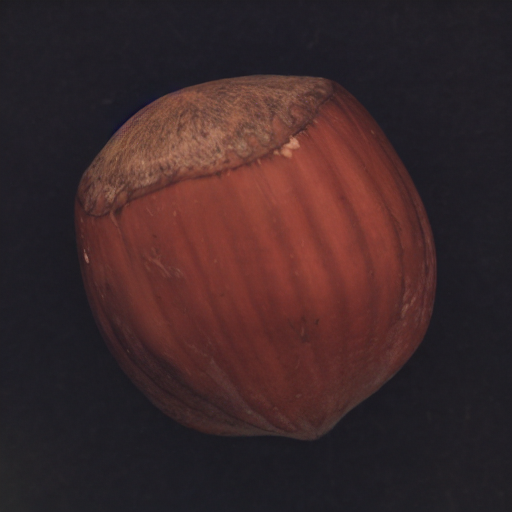

VAE 복원 완료


In [14]:
import torch
import numpy as np
from PIL import Image
from IPython.display import display

# 기존 입력 이미지 사용
x = np.asarray(BASE_INPUT, dtype=np.float32)
x = torch.from_numpy(x).permute(2, 0, 1).unsqueeze(0)
x = (x / 127.5 - 1.0).to("cuda")

stable.vae.eval()

with torch.no_grad():
    with torch.autocast("cuda", dtype=torch.float16):
        z = stable.vae.encode(x).latent_dist.mode()
        z = z * stable.vae.config.scaling_factor

        reconstructed = stable.vae.decode(
            z / stable.vae.config.scaling_factor
        ).sample

def check_tensor(name, value):
    finite = torch.isfinite(value)
    print(f"{name}")
    print(" dtype:", value.dtype)
    print(" shape:", tuple(value.shape))
    print(" 유효 값 비율:", round(finite.float().mean().item() * 100, 3), "%")

    if finite.any():
        valid = value[finite]
        print(" min:", valid.min().item())
        print(" max:", valid.max().item())

    return bool(finite.all().item())

print("=== FP16 VAE 진단 ===")

z_ok = check_tensor("Encoded Latent", z)
recon_ok = check_tensor("Reconstructed Image", reconstructed)

if z_ok and recon_ok:
    output = (reconstructed / 2 + 0.5).clamp(0, 1)
    output = output[0].permute(1, 2, 0).float().cpu().numpy()
    output = Image.fromarray((output * 255).astype(np.uint8))

    display(output)
    print("VAE 복원 완료")
else:
    print("VAE 과정에서 NaN 또는 Inf가 발견되었습니다.")

del x, z, reconstructed
torch.cuda.empty_cache()

In [15]:
original_update = stable._update_latent

def checked_update(latents, loss, step_size, return_grad=False):

    if not torch.isfinite(latents).all().item():
        raise FloatingPointError(
            "기울기 업데이트 이전에 Latent에서 NaN/Inf 발생"
        )

    if not torch.isfinite(loss).all().item():
        raise FloatingPointError(
            "기울기 업데이트 이전에 Loss에서 NaN/Inf 발생"
        )

    result = original_update(
        latents=latents,
        loss=loss,
        step_size=step_size,
        return_grad=return_grad
    )

    updated = result[0] if isinstance(result, tuple) else result

    if not torch.isfinite(updated).all().item():
        raise FloatingPointError(
            "기울기 업데이트 이후 Latent에서 NaN/Inf 발생"
        )

    return result

stable._update_latent = checked_update

print("수치 이상 조기 감지 기능 적용 완료")

수치 이상 조기 감지 기능 적용 완료


## 4. 결함 토큰 선택과 생성 함수 정의

여기서는 실제 생성 실험에 들어가기 전에, 프롬프트 안에서 결함 단어의 토큰 위치를 찾고 각 조건별 이미지를 만드는 함수를 정의한다.

### 내가 바꾼 이유
원래 수업 코드에서는 토큰 인덱스를 고정값으로 두었는데, 프롬프트가 바뀌면 잘못된 단어를 선택할 가능성이 있었다.  
그래서 문장 안에서 `crack`에 해당하는 토큰 위치를 찾는 방식으로 바꾸었다.

또한 실행 중 발생한 메모리 문제, dtype 문제, NaN 문제를 줄이기 위해 안전장치도 함께 넣었다.


In [16]:
import torch
import torch.nn.functional as F
from utils import ptp_utils

Processor = ptp_utils.AttendExciteCrossAttnProcessor

if not hasattr(Processor, "_original_call"):
    Processor._original_call = Processor.__call__

def memory_efficient_attention(
    self,
    attn,
    hidden_states,
    encoder_hidden_states=None,
    attention_mask=None
):
    # Cross-Attention은 원본 방식 유지
    # Self-Attention에 별도의 마스크가 있으면 원본 사용
    if encoder_hidden_states is not None or attention_mask is not None:
        return Processor._original_call(
            self, attn, hidden_states,
            encoder_hidden_states, attention_mask
        )

    # Self-Attention의 Q, K, V 계산
    query = attn.head_to_batch_dim(attn.to_q(hidden_states))
    key = attn.head_to_batch_dim(attn.to_k(hidden_states))
    value = attn.head_to_batch_dim(attn.to_v(hidden_states))

    # 전체 Attention 행렬 생성을 피하는 연산
    output = F.scaled_dot_product_attention(
        query.unsqueeze(0),
        key.unsqueeze(0),
        value.unsqueeze(0),
        dropout_p=0.0,
        is_causal=False
    ).squeeze(0)

    # AnomalyAny AttentionStore의 레이어 카운터 유지
    # Self-Attention 값 자체는 저장하지 않음
    placeholder = query.new_empty((1, 1025, 1))
    self.attnstore(placeholder, False, self.place_in_unet)

    output = attn.batch_to_head_dim(output)
    output = attn.to_out[0](output)
    output = attn.to_out[1](output)

    return output

Processor.__call__ = memory_efficient_attention

# VAE 메모리 절약
stable.vae.enable_slicing()

# GPU 메모리 확인
free, total = torch.cuda.mem_get_info()

print("메모리 최적화 적용 완료")
print(f"전체 VRAM: {total / 1024**3:.2f} GB")
print(f"사용 가능한 VRAM: {free / 1024**3:.2f} GB")

메모리 최적화 적용 완료
전체 VRAM: 6.00 GB
사용 가능한 VRAM: 2.72 GB


In [17]:
# 이 셀은 결함 토큰 탐색과 조건별 생성 함수 정의를 포함한다.
# 원래 수업 코드에서는 토큰 인덱스를 고정했지만, 프롬프트가 달라질 때 더 안전하게 동작하도록 수정했다.

assert 'TOKENIZER' in globals(), '4번 모델 로드 셀을 먼저 실행하세요.'

def defect_tokens(sentence, target='crack'):
    ids=TOKENIZER(sentence,add_special_tokens=True)['input_ids']
    needle=TOKENIZER(target,add_special_tokens=False)['input_ids']
    hits=[]
    for i in range(len(ids)-len(needle)+1):
        if ids[i:i+len(needle)]==needle:
            hits=list(range(i,i+len(needle)))
            break
    if not hits:
        hits=[i for i,idx in enumerate(ids) if target.lower() in TOKENIZER.decode([idx]).lower()]
    if not hits:
        words=[(i,TOKENIZER.decode([idx])) for i,idx in enumerate(ids)]
        raise ValueError(f'결함 단어 {target}의 토큰 위치를 찾지 못했습니다: {words}')
    return hits

def signature_of(exp):
    init,roi=get_input(exp)
    prompt,normal,detailed=build_text(exp)
    cfg={'exp':asdict(exp),'model_id':MODEL_ID,'dtype':str(MODEL_DTYPE),
         'num_steps':NUM_DIFFUSION_STEPS,'guidance_scale':GUIDANCE_SCALE,
         'scale_factor':SCALE_FACTOR,'prompt':prompt,'normal':normal,'detailed':detailed,
         'input_hash':hashlib.sha256(np.array(init).tobytes()).hexdigest(),
         'roi_hash':hashlib.sha256(np.array(roi).tobytes()).hexdigest()}
    return hashlib.sha256(json.dumps(cfg,sort_keys=True).encode('utf-8')).hexdigest()

def generate_condition(exp):
    image_path,meta_path=output_paths(exp)
    fingerprint=signature_of(exp)
    if RESUME_EXISTING and image_path.is_file() and meta_path.is_file():
        try:
            old=json.loads(meta_path.read_text(encoding='utf-8'))
            if old.get('signature')==fingerprint:
                print('[저장된 결과 재사용]',exp.name)
                return 'cached'
        except (OSError,ValueError):
            pass
    src,roi=get_input(exp)
    prompt,normal,detailed=build_text(exp)
    tokens=defect_tokens(prompt)
    print(f'[{exp.name}] seed={exp.seed}, mask={exp.use_mask}, init={exp.init_guidance}, '
          f'tokens={tokens}, detailed={exp.prompt_style}')
    cfg=RunConfig(prompt=prompt,run_standard_sd=False,output_path=OUTPUT_DIR/'config_tmp',
                  scale_factor=SCALE_FACTOR,n_inference_steps=NUM_DIFFUSION_STEPS,
                  guidance_scale=GUIDANCE_SCALE,max_iter_to_alter=25)
    torch.manual_seed(exp.seed)
    torch.cuda.manual_seed_all(exp.seed)
    np.random.seed(exp.seed)
    generator=torch.Generator(device='cuda').manual_seed(exp.seed)
    controller=AttentionStore()
    t0=time.perf_counter()
    result=None
    try:
        # half-precision weights + float32 intermediate tensors are mixed by AnomalyAny.
        # Run the ENTIRE pipeline under CUDA autocast to prevent Float/Half linear failures.
        # Keep torch.enable_grad blocks inside AnomalyAny intact (no inference_mode!).
        with torch.autocast(device_type='cuda', dtype=MODEL_DTYPE):
            result, latent=run_on_prompt_and_masked_image(
                model=stable,prompt=[prompt],controller=controller,
                token_indices=tokens,init_image=src,
                init_image_guidance_scale=exp.init_guidance,
                mask_image=roi if exp.use_mask else None,
                seed=generator,config=cfg,normal_prompt=normal,detailed_prompt=detailed)
        # 원본 run.py 반환: (outputs[0], image_latents), outputs[0]은 보통 PIL 이미지 리스트
        if isinstance(result,(list,tuple)):
            if not result:raise RuntimeError('모델이 빈 이미지 리스트를 반환했습니다.')
            result=result[0]
        if not isinstance(result,Image.Image):
            raise TypeError(f'생성 이미지 타입이 예상과 다릅니다: {type(result)}')
        saved=to_rgb512(result)
        seconds=round(time.perf_counter()-t0,3)
        saved.save(image_path)
        metadata={**asdict(exp),'signature':fingerprint,'model_id':MODEL_ID,
                  'model_dtype':str(MODEL_DTYPE),'num_diffusion_steps':NUM_DIFFUSION_STEPS,
                  'guidance_scale':GUIDANCE_SCALE,'scale_factor':SCALE_FACTOR,
                  'seconds':seconds,'prompt':prompt,'normal_prompt':normal,
                  'detailed_prompt':detailed,'token_indices':tokens,
                  'source_file':str(new_path if exp.source=='new_product' else base_path)}
        meta_path.write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
        print(f'[저장 완료] {image_path.name} / {seconds:.1f}초')
        return 'generated'
    finally:
        if 'latent' in locals():del latent
        if 'saved' in locals():del saved
        if result is not None:del result
        del controller,generator
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()

## 5. 8개 조건 생성 및 실행 시간 기록

이 부분은 실제 이미지 생성 실험을 실행하는 핵심 단계이다.  
처음에는 8개 조건 전체를 비교하려고 했지만, GPU 메모리와 실행 시간 문제 때문에 먼저 기준 실험을 안정적으로 성공시키는 것을 우선 목표로 삼았다.

### 내가 세운 전략
- 먼저 `E00_baseline`만 실행해서 생성 자체가 되는지 본다.
- 결과가 저장되면 그 다음에 마스크, 프롬프트, Seed, 새 제품, 이미지 가이던스 조건을 추가한다.
- 실행 실패도 결과의 일부라고 보고, 어떤 오류가 발생했는지도 기록한다.

### 실제 진행 중 느낀 점
처음에는 이미지가 생성되기만 하면 성공이라고 생각했는데, 검은 이미지가 나오거나 제품 형상이 과도하게 무너지는 경우도 있어서 "실행 성공"과 "쓸 수 있는 데이터 생성"은 다르다는 걸 확인했다.


In [19]:
import torch

# 이전에 모델 객체에 덮어쓴 함수를 제거
if "_update_latent" in vars(stable):
    delattr(stable, "_update_latent")

# 원래 클래스에 정의된 함수 가져오기
base_update = type(stable)._update_latent

def checked_update(latents, loss, step_size, return_grad=False):

    if not torch.isfinite(latents).all().item():
        raise FloatingPointError(
            "Latent 업데이트 이전에 NaN/Inf 발생"
        )

    if isinstance(loss, torch.Tensor):
        if not torch.isfinite(loss).all().item():
            raise FloatingPointError(
                "Loss에서 NaN/Inf 발생"
            )

    result = base_update(
        latents=latents,
        loss=loss,
        step_size=step_size,
        return_grad=return_grad
    )

    updated = result[0] if isinstance(result, tuple) else result

    if not torch.isfinite(updated).all().item():
        raise FloatingPointError(
            "Latent 업데이트 이후 NaN/Inf 발생"
        )

    return result

# 수정된 진단 함수 등록
stable._update_latent = checked_update

print("재귀 호출 문제 수정 완료")
print("진단 함수 등록:", stable._update_latent.__name__)

재귀 호출 문제 수정 완료
진단 함수 등록: checked_update


In [21]:
import torch

# _prompt_update 원본 클래스 메서드 참조
base_prompt_update = type(stable)._prompt_update

def safe_prompt_update(
    *,
    prompt_embeds,
    prompt_embeds_original,
    normal_embeds,
    indices_to_alter,
    curr_step_size=0.05
):
    try:
        # float32로 올려서 더 안정적으로 시도
        pe = prompt_embeds.float().detach().clone().requires_grad_(True)
        po = prompt_embeds_original.float().detach()
        ne = normal_embeds.float().detach()

        out = base_prompt_update(
            stable,
            prompt_embeds=pe,
            prompt_embeds_original=po,
            normal_embeds=ne,
            indices_to_alter=indices_to_alter,
            curr_step_size=curr_step_size
        )

        if not torch.isfinite(out).all().item():
            print("prompt update에서 NaN/Inf 발생 -> 원래 prompt_embeds로 대체")
            return prompt_embeds

        return out.to(dtype=prompt_embeds.dtype)

    except Exception as e:
        print("prompt update 실패:", repr(e))
        print("원래 prompt_embeds로 대체")
        return prompt_embeds

# 인스턴스에 안전 버전 등록
stable._prompt_update = safe_prompt_update

print("safe _prompt_update 적용 완료")

safe _prompt_update 적용 완료


In [22]:
# 이 셀은 실제 생성 실험을 실행하는 메인 루프이다.
# 처음에는 baseline 한 장만 실행해 저장 여부와 품질을 먼저 확인하고, 이후 필요한 조건을 추가로 실행하도록 했다.

assert 'generate_condition' in globals(), '5번 생성 함수 정의 셀을 먼저 실행하세요.'
RUN_NAMES=['E00_baseline']  # 먼저 한 건 성공 확인 후 'ALL'로 변경
selected=ACTIVE_EXPERIMENTS if RUN_NAMES=='ALL' else [e for e in ACTIVE_EXPERIMENTS if e.name in RUN_NAMES]
if not selected:raise ValueError('선택한 조건에 사용 가능한 입력 사진이 없습니다. NEW_IMAGE_PATH를 확인하세요.')
if PENDING_EXPERIMENTS:
    print('[미완료 조건]',[e.name for e in PENDING_EXPERIMENTS],': 신규 사진을 연결한 뒤 반드시 추가로 실행하세요.')
run_log=[]
for i,exp in enumerate(selected,1):
    print(f'\n===== [{i}/{len(selected)}] {exp.name} =====',flush=True)
    t0=time.perf_counter()
    try:
        status=generate_condition(exp)
        run_log.append({'name':exp.name,'status':status,'elapsed_s':round(time.perf_counter()-t0,2)})
    except Exception as error:
        print('\n[생성 오류] 조건:',exp.name,'오류:',repr(error))
        (OUTPUT_DIR/'last_error.txt').write_text(
            f'{exp.name}: {repr(error)}\n{traceback.format_exc()}',encoding='utf-8')
        raise
pd.DataFrame(run_log).to_csv(OUTPUT_DIR/'run_log.csv',index=False,encoding='utf-8-sig')
display(pd.DataFrame(run_log))
print('완료된 조건:',len(run_log),'/',len(EXPERIMENTS))


===== [1/1] E00_baseline =====
[E00_baseline] seed=2026, mask=False, init=0.3, tokens=[8], detailed=detailed


C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data\AnomalyAny\clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels
 31%|███▏      | 5/16 [06:01<13:15, 72.35s/it]


[저장 완료] E00_baseline.png / 391.6초


,name,status,elapsed_s
0,E00_baseline,generated,392.72


완료된 조건: 1 / 8


## 6. 정량 평가

이 단계에서는 원본 이미지와 생성 이미지를 비교해 픽셀 기준 변화량을 계산한다.  
여기서 사용하는 ROI는 실제 정답 결함 마스크가 아니라, 결함이 생길 것이라고 예상한 영역이다.

### 지표 해석 시 주의할 점
- `roi_mae`가 크다고 해서 결함 생성이 잘 되었다고 단정할 수 없다.
- `outside_mae`가 크면 원래 보존되어야 할 정상 영역도 많이 변형되었다는 뜻이다.
- 결국 자동 지표만으로는 결함의 현실성을 완전히 판단할 수 없기 때문에, 뒤에서 수동 평가를 추가했다.

### 내 생각
이번 프로젝트에서 가장 중요한 배움은 "수치가 곧 품질은 아니다"라는 점이었다.


In [23]:
# 이 셀은 생성된 결과를 정량 평가하는 함수와 실행 코드이다.
# ROI 내부 변화와 ROI 외부 변화를 함께 계산해, 결함이 국소적으로 생겼는지 아니면 전체가 같이 무너졌는지 확인하려고 했다.

assert 'INPUT_BY_SOURCE' in globals() and 'EXPERIMENTS' in globals(), '1~2번 준비 셀이 필요합니다.'

def measure(exp):
    img_p,meta_p=output_paths(exp)
    if not img_p.is_file() or not meta_p.is_file():
        return None
    try:meta=json.loads(meta_p.read_text(encoding='utf-8'))
    except (ValueError,OSError):return None
    if meta.get('signature')!=signature_of(exp):
        print('조건/입력이 변경되어 분석 제외:',exp.name)
        return None
    original,mask=get_input(exp)
    generated=to_rgb512(img_p)
    difference=np.abs(np.asarray(original,dtype=np.float32)-np.asarray(generated,dtype=np.float32)).mean(axis=2)
    roi=(np.asarray(mask)>127)
    inside=difference[roi];outside=difference[~roi]
    total=float(difference.sum())
    return {**asdict(exp), 'seconds':float(meta['seconds']),
            'roi_area_pct':float(roi.mean()*100),
            'roi_mae':float(inside.mean()),'outside_mae':float(outside.mean()),
            'roi_changed_pct':float((inside>=PIXEL_CHANGE_THRESHOLD).mean()*100),
            'outside_changed_pct':float((outside>=PIXEL_CHANGE_THRESHOLD).mean()*100),
            'roi_share_pct':float(difference[roi].sum()/total*100) if total>0 else 0.,
            'total_mae':float(difference.mean())}

records=[row for e in ACTIVE_EXPERIMENTS if (row:=measure(e)) is not None]
metrics=pd.DataFrame(records)
if metrics.empty:
    print('아직 현재 설정과 일치하는 생성 이미지가 없습니다. 6번 생성 셀을 실행하세요.')
else:
    metrics=metrics.round(3)
    metrics.to_csv(OUTPUT_DIR/'metrics.csv',index=False,encoding='utf-8-sig')
    display(metrics[['name','source','seed','use_mask','init_guidance','prompt_style',
                     'roi_mae','outside_mae','roi_share_pct','seconds']])
    print('분석 성공:',len(metrics),'/',len(EXPERIMENTS))

,name,source,seed,use_mask,init_guidance,prompt_style,roi_mae,outside_mae,roi_share_pct,seconds
0,E00_baseline,hazelnut,2026,False,0.3,detailed,29.321,22.638,13.829,391.627


분석 성공: 1 / 8


## 7. 비교 이미지와 그래프 정리

이 부분은 원본, ROI, 생성 결과, 차이 이미지를 한눈에 보여 주고, 정량 평가 지표를 그래프로 정리하는 단계이다.

### 내가 이 그래프를 넣은 이유
결과 이미지만 보면 직관적이지만, 어떤 부분이 많이 변했는지는 수치가 있어야 더 설득력 있게 설명할 수 있다.  
반대로 수치만 보면 실제 이미지가 얼마나 이상하게 변했는지 놓칠 수 있기 때문에 둘을 같이 보도록 구성했다.


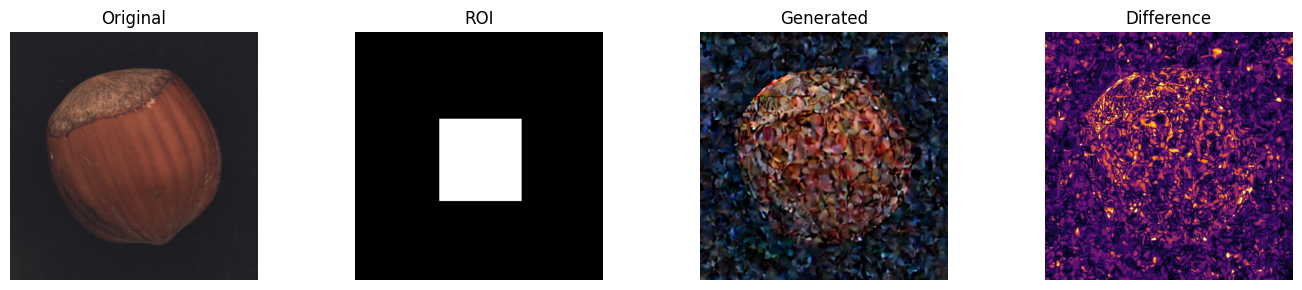

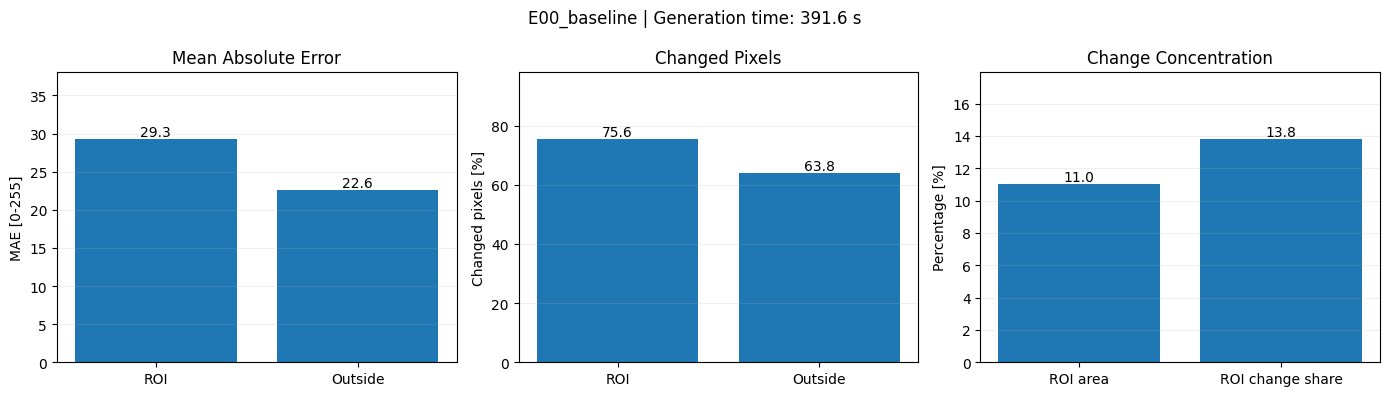

그래프 저장 완료


In [25]:
# 이 셀은 원본 / ROI / 생성 / 차이 이미지를 시각화하고 그래프로 저장한다.
# 결과 이미지만 보는 것보다 변화의 위치와 정도를 더 설득력 있게 설명할 수 있다.

import numpy as np
import matplotlib.pyplot as plt

assert "metrics" in globals(), "7번 정량 평가를 먼저 실행하세요."

if metrics.empty:
    print("분석할 결과가 없습니다.")

else:
    # 1. 원본 / 마스크 / 생성 / 차이 이미지
    fig, axes = plt.subplots(
        len(records), 4,
        figsize=(14, 3 * len(records)),
        squeeze=False
    )

    for i, record in enumerate(records):
        exp = next(
            e for e in EXPERIMENTS
            if e.name == record["name"]
        )

        original, mask = get_input(exp)
        generated = to_rgb512(output_paths(exp)[0])

        delta = np.abs(
            np.asarray(original, dtype=np.float32)
            - np.asarray(generated, dtype=np.float32)
        ).mean(axis=2)

        images = [original, mask, generated, delta]
        titles = ["Original", "ROI", "Generated", "Difference"]

        for ax, img, title in zip(axes[i], images, titles):
            if isinstance(img, np.ndarray):
                ax.imshow(img, cmap="inferno", vmin=0, vmax=100)
            elif img.mode == "L":
                ax.imshow(img, cmap="gray", vmin=0, vmax=255)
            else:
                ax.imshow(img)

            ax.set_title(title)
            ax.axis("off")

        axes[i, 0].set_ylabel(exp.name)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "comparison_all.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # 2. 기준 실험의 정량 결과 요약
    base_rows = metrics[metrics["name"] == "E00_baseline"]
    m = base_rows.iloc[0] if not base_rows.empty else metrics.iloc[0]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    chart_data = [
        (
            ["ROI", "Outside"],
            [m["roi_mae"], m["outside_mae"]],
            "Mean Absolute Error",
            "MAE [0-255]"
        ),
        (
            ["ROI", "Outside"],
            [m["roi_changed_pct"], m["outside_changed_pct"]],
            "Changed Pixels",
            "Changed pixels [%]"
        ),
        (
            ["ROI area", "ROI change share"],
            [m["roi_area_pct"], m["roi_share_pct"]],
            "Change Concentration",
            "Percentage [%]"
        )
    ]

    for ax, (labels, values, title, ylabel) in zip(axes, chart_data):
        bars = ax.bar(labels, values)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.set_ylim(0, max(values) * 1.3 if max(values) > 0 else 1)
        ax.grid(axis="y", alpha=0.2)

        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                f"{value:.1f}",
                ha="center",
                va="bottom"
            )

    fig.suptitle(
        f"{m['name']} | Generation time: {m['seconds']:.1f} s"
    )
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "graph_baseline_summary.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # 3. 추가 생성 결과가 있을 때만 조건 간 비교
    if len(metrics) >= 2:
        fig, ax = plt.subplots(figsize=(11, 4))

        x = np.arange(len(metrics))
        width = 0.35

        ax.bar(
            x - width / 2,
            metrics["roi_mae"],
            width,
            label="ROI MAE"
        )

        ax.bar(
            x + width / 2,
            metrics["outside_mae"],
            width,
            label="Outside MAE"
        )

        ax.set_xticks(x)
        ax.set_xticklabels(metrics["name"], rotation=30, ha="right")
        ax.set_ylabel("MAE [0-255]")
        ax.set_title("Comparison Between Experiments")
        ax.legend()
        ax.grid(axis="y", alpha=0.2)

        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / "graph_experiment_comparison.png",
            dpi=160,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

    print("그래프 저장 완료")

## 8. 다섯 가지 실험별 비교

원래 계획은 마스크, 프롬프트, Seed, 새 제품, 이미지 가이던스까지 모두 비교하는 것이었다.  
다만 현재 시점에서는 기준 실험이 먼저 성공했고, 나머지 조건은 추가로 생성하면서 비교를 이어 가는 방식으로 진행했다.

### 이 부분의 의미
비교 실험은 단순히 결과를 많이 만드는 것이 아니라, "어떤 조건이 어떤 변화에 영향을 주는지"를 분리해서 보는 데 목적이 있다.


In [26]:
# 이 셀은 여러 실험 조건이 생성되었을 때 수치 비교를 쉽게 보기 위한 요약 표이다.
# 현재는 baseline만 생성되었더라도, 이후 추가 실험을 돌리면 같은 구조로 이어서 비교할 수 있다.

assert 'metrics' in globals(), '7번 정량 평가 셀을 먼저 실행하세요.'
pairs=[('1. Mask',['E00_baseline','E01_mask_on']),
       ('2. Prompt',['E00_baseline','E02_simple_prompt']),
       ('3. Seed',['E00_baseline','E03_seed_plus1','E04_seed_plus2']),
       ('4. New product',['E00_baseline','E05_new_product']),
       ('5. Init guidance',['E06_init_020','E00_baseline','E07_init_045'])]
if metrics.empty:
    print('아직 수치 결과 없음')
else:
    byname=metrics.set_index('name')
    for title,names in pairs:
        print('\n'+title)
        found=[n for n in names if n in byname.index]
        if len(found)>0:
            if len(found)<len(names): print('부분 완료 - 없는 조건:',sorted(set(names)-set(found)))
            display(byname.loc[found,['source','seed','use_mask','init_guidance','prompt_style',
                                      'roi_mae','outside_mae','roi_share_pct','seconds']])
        else:
            print('완료된 조건 없음')


1. Mask
부분 완료 - 없는 조건: ['E01_mask_on']


,source,seed,use_mask,init_guidance,prompt_style,roi_mae,outside_mae,roi_share_pct,seconds
name,,,,,,,,,
E00_baseline,hazelnut,2026,False,0.3,detailed,29.321,22.638,13.829,391.627



2. Prompt
부분 완료 - 없는 조건: ['E02_simple_prompt']


,source,seed,use_mask,init_guidance,prompt_style,roi_mae,outside_mae,roi_share_pct,seconds
name,,,,,,,,,
E00_baseline,hazelnut,2026,False,0.3,detailed,29.321,22.638,13.829,391.627



3. Seed
부분 완료 - 없는 조건: ['E03_seed_plus1', 'E04_seed_plus2']


,source,seed,use_mask,init_guidance,prompt_style,roi_mae,outside_mae,roi_share_pct,seconds
name,,,,,,,,,
E00_baseline,hazelnut,2026,False,0.3,detailed,29.321,22.638,13.829,391.627



4. New product
부분 완료 - 없는 조건: ['E05_new_product']


,source,seed,use_mask,init_guidance,prompt_style,roi_mae,outside_mae,roi_share_pct,seconds
name,,,,,,,,,
E00_baseline,hazelnut,2026,False,0.3,detailed,29.321,22.638,13.829,391.627



5. Init guidance
부분 완료 - 없는 조건: ['E06_init_020', 'E07_init_045']


,source,seed,use_mask,init_guidance,prompt_style,roi_mae,outside_mae,roi_share_pct,seconds
name,,,,,,,,,
E00_baseline,hazelnut,2026,False,0.3,detailed,29.321,22.638,13.829,391.627


## 9. 수동 평가

자동 계산으로는 결함이 실제로 자연스러운지 판단하기 어렵기 때문에, 생성된 결과를 직접 보고 점수와 코멘트를 남긴다.

### 수동 평가 항목
- `defect_fidelity_1to5`: 요청한 결함이 얼마나 잘 표현되었는가
- `product_preservation_1to5`: 원래 제품 형상이 얼마나 유지되었는가
- `comments`: 이미지에서 직접 관찰한 내용

### 내 생각
이 부분은 사람이 직접 판단한다는 점에서 주관적이지만, 오히려 실제 프로젝트에서는 꼭 필요한 과정이라고 느꼈다.


In [27]:
# 이 셀은 자동 수치만으로 판단하기 어려운 결함 품질을 사람이 직접 평가하기 위한 CSV를 만든다.
# 이번 프로젝트에서는 최종적으로 수동 평가가 꼭 필요하다고 판단했다.

assert 'metrics' in globals(), '7번 정량 평가 셀을 먼저 실행하세요.'
manual_csv=OUTPUT_DIR/'manual_review.csv'
if not metrics.empty:
    existing=(pd.read_csv(manual_csv,encoding='utf-8-sig') if manual_csv.is_file()
              else pd.DataFrame(columns=['name','defect_fidelity_1to5','product_preservation_1to5','comments']))
    newrows=pd.DataFrame([{'name':name} for name in metrics['name']])
    review=newrows.merge(existing,on='name',how='left')
    for col in ['defect_fidelity_1to5','product_preservation_1to5','comments']:
        if col not in review:review[col]=''
    review.to_csv(manual_csv,index=False,encoding='utf-8-sig')
    display(review)
    print('수동 평가 기록:',manual_csv)
else:
    print('먼저 분석 결과를 생성하세요.')

,name,defect_fidelity_1to5,product_preservation_1to5,comments
0,E00_baseline,NaN,NaN,NaN


수동 평가 기록: C:\Users\USER\Desktop\ERICA_X_MODULABS_CV\08_Gen_Synthetic_data\results\manual_review.csv


In [28]:
import pandas as pd

review_path = OUTPUT_DIR / "manual_review.csv"

review = pd.read_csv(
    review_path,
    encoding="utf-8-sig"
)

# 기준 이미지에 대한 수동 평가
mask = review["name"] == "E00_baseline"

review.loc[mask, "defect_fidelity_1to5"] = 1
review.loc[mask, "product_preservation_1to5"] = 2

review.loc[mask, "comments"] = (
    "균열이 명확하게 표현되지 않았으며, "
    "헤이즐넛의 기존 형상과 배경이 크게 변형되었다. "
    "결함의 국소적 생성보다 전체적인 질감 변화가 두드러졌다."
)

review.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

display(review)
print("수동 평가 저장 완료")

C:\Users\USER\AppData\Local\Temp\ipykernel_23168\3551596000.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '균열이 명확하게 표현되지 않았으며, 헤이즐넛의 기존 형상과 배경이 크게 변형되었다. 결함의 국소적 생성보다 전체적인 질감 변화가 두드러졌다.' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  review.loc[mask, "comments"] = (


,name,defect_fidelity_1to5,product_preservation_1to5,comments
0,E00_baseline,1.0,2.0,"균열이 명확하게 표현되지 않았으며, 헤이즐넛의 기존 형상과 배경이 크게 변형되었다...."


수동 평가 저장 완료


## 10. 제출 전 정리와 개인 회고

### 이번 프로젝트에서 확인한 점
- AnomalyAny 기반 결함 생성은 실제로 동작시킬 수 있었지만, 안정적으로 실행하기 위해 여러 수정이 필요했다.
- 기준 실험 `E00_baseline`은 생성에 성공했고, 정량 지표와 수동 평가를 통해 품질을 검토했다.
- 생성 이미지가 검은 화면으로 나오는 문제, NaN 문제, dtype 문제, 실행 시간 문제를 직접 겪으면서 생성 모델 결과를 그대로 신뢰하면 안 된다는 점을 배웠다.

### Keep
- 기준 조건을 먼저 정하고, 한 번에 하나의 조건만 바꾸는 비교 실험 구조는 유지하고 싶다.
- 자동 지표와 시각적 결과를 함께 보는 방식도 계속 사용하고 싶다.

### Problem
- RTX 4050 환경에서는 실행 시간이 길고, 여러 번의 안정화 과정이 필요했다.
- 생성은 성공했지만 결함이 자연스럽게 표현되지 않고 정상 영역도 함께 많이 바뀌는 문제가 있었다.

### Try
- 마스크 실험을 먼저 추가로 돌려 정상 영역 변화가 줄어드는지 확인해 보고 싶다.
- 새 제품 실험도 안정적으로 동작하는지 확인하고 싶다.

### Action After Review
- 다음에는 생성 성공 여부만 보지 않고, 결과 이미지의 현실성과 활용 가능성을 먼저 확인하겠다.
- 이후에는 합성 결함 이미지를 실제 결함 검출 모델 학습에 추가했을 때 성능이 좋아지는지도 검증해 보고 싶다.